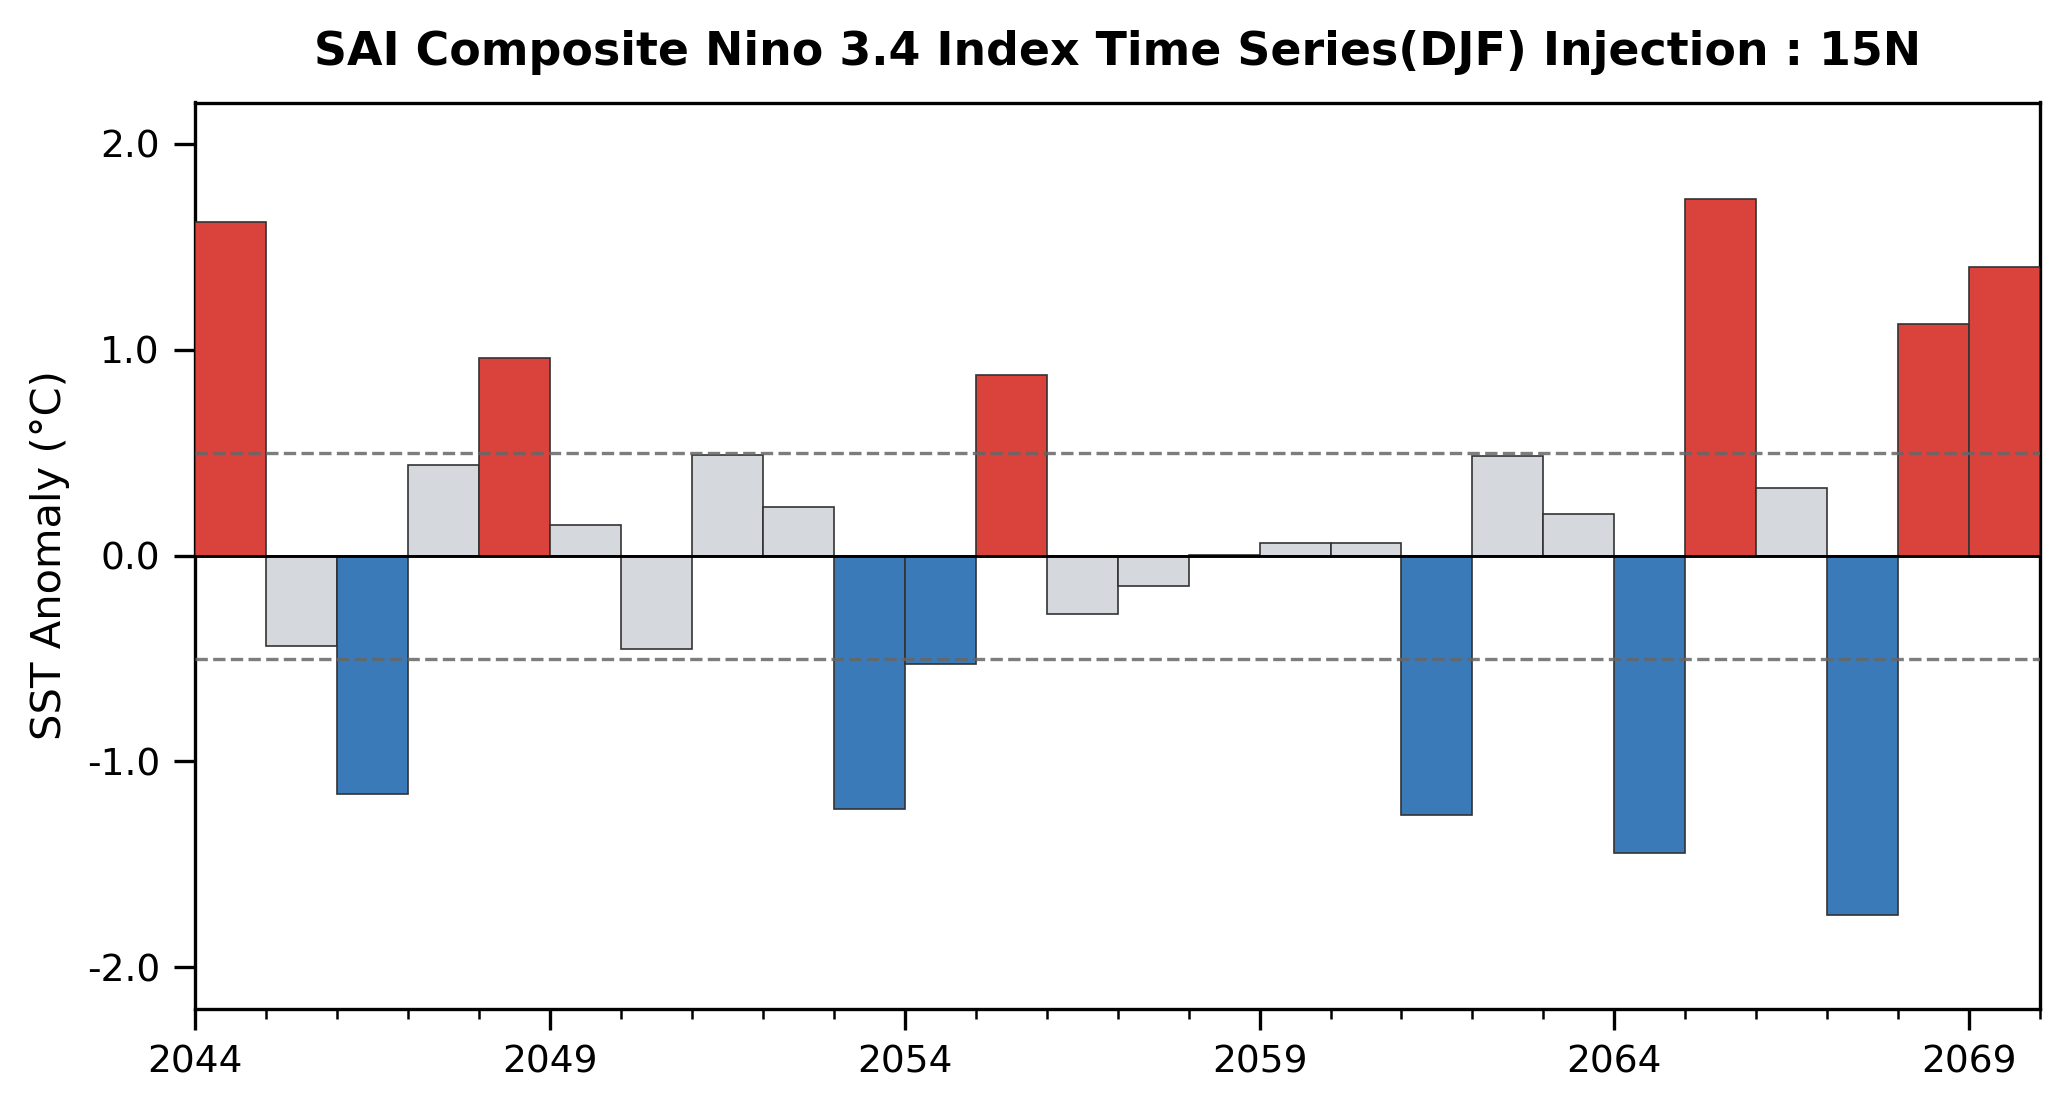

In [1]:
# nino 3.4 index 단일 위도 주입에 대한 그래프(1개)

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

file_path = 'nino34_djf_15N.nc'
ds = xr.open_dataset(file_path, decode_times=False)

values = ds['TS'].squeeze().values
n_steps = len(values)
start_year = 2044
years = np.arange(start_year, start_year + n_steps)

colors = []
for v in values:
  if v >= 0.5:
    colors.append('#D9433B')  # 엘니뇨
  elif v <= -0.5:
    colors.append('#3B7AB8')  # 라니냐
  else:
    colors.append('#D5D8DC')  # 기준점에 미치지 못한 값 (neutral)

fig, ax = plt.subplots(figsize=(7.0, 3.8), dpi=300)

ax.bar(
    years,
    values,
    color=colors,
    width=1.0,
    edgecolor='#333333',
    linewidth=0.4,
    align='edge',
    zorder=3,
)

# 가로
ax.axhline(0.0, color='black', linewidth=0.7, zorder=4)  # 0선

# +-0.5 기준선

ax.axhline(
    0.5,
    color='#666666',
    linestyle='--',
    linewidth=0.8,
    alpha=0.85,
    zorder=4,
    label='Threshold (±0.5°C)',
)
ax.axhline(
    -0.5, color='#666666', linestyle='--', linewidth=0.8, alpha=0.85, zorder=4
)

# x축 y축

ax.set_ylim(-2.2, 2.2)
ax.set_yticks(np.arange(-2.0, 2.1, 1.0))
ax.set_yticklabels([f'{y:.1f}' for y in np.arange(-2.0, 2.1, 1.0)], fontsize=9)

ax.set_xlim(years[0], years[-1] + 1)
major_ticks = np.arange(start_year, start_year + n_steps + 1, 5)
ax.set_xticks(major_ticks)
ax.set_xticks(np.arange(start_year, start_year + n_steps + 1, 1), minor=True)
ax.set_xticklabels(major_ticks, fontsize=9)

ax.tick_params(
    which='major', direction='out', length=5, width=0.8, top=False, right=False
)
ax.tick_params(
    which='minor',
    direction='out',
    length=2.5,
    width=0.6,
    top=False,
    right=False,
)

for spine in ax.spines.values():
  spine.set_linewidth(0.8)

ax.set_ylabel('SST Anomaly (°C)', fontsize=10)
ax.set_title(
    'SAI Composite Nino 3.4 Index Time Series(DJF) Injection : 15N',
    fontsize=11,
    fontweight='bold',
    pad=9,
)

plt.tight_layout()
plt.savefig('nino34_djf_INJANN15N.png', dpi=300)
plt.show()

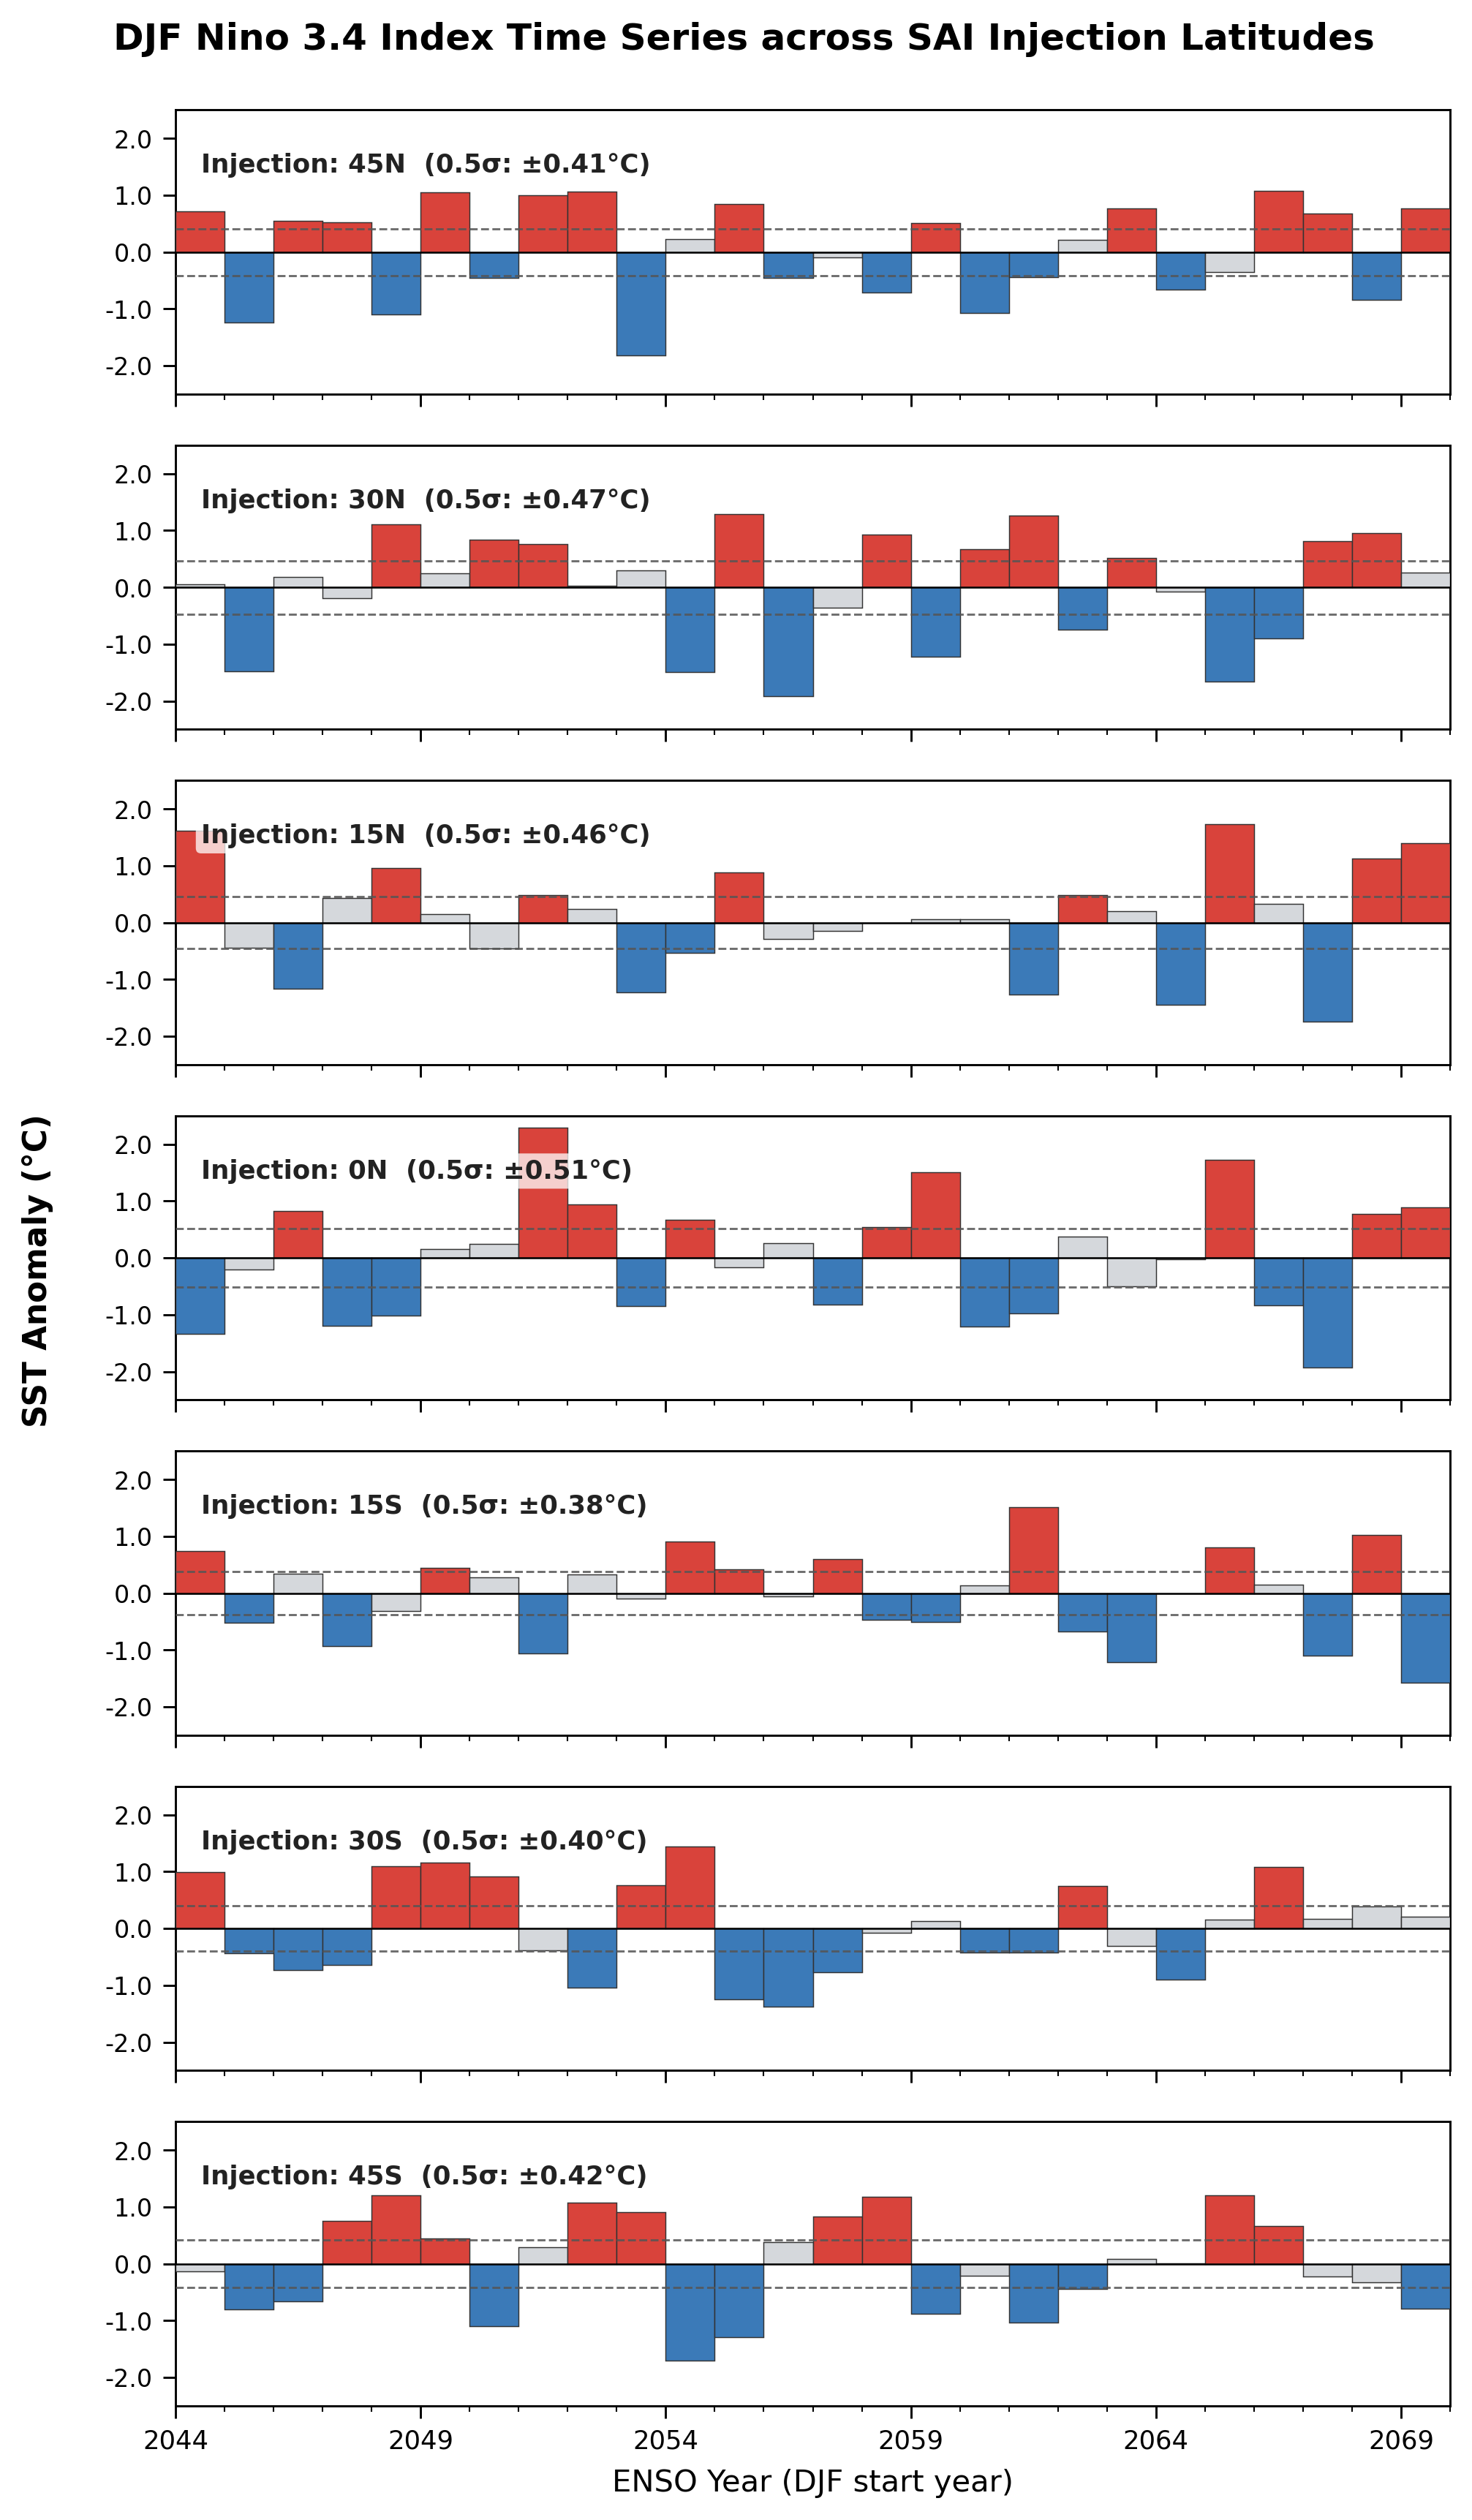

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

injections = ['45N', '30N', '15N', '0N', '15S', '30S', '45S']

# 7 * 1 프레임

fig, axes = plt.subplots(
    nrows=len(injections),
    ncols=1,
    figsize=(7.0, 11.5),
    dpi=300,
    sharex=True,
    sharey=True,
)

start_year = 2044

for ax, inj in zip(axes, injections):
  file_path = f'nino34_djf_{inj}.nc'

  try:
    ds = xr.open_dataset(file_path, decode_times=False)
    values = ds['TS'].squeeze().values
    n_steps = len(values)
  except FileNotFoundError:
    # 파일 없는 경우 더미 데이터 처리
    n_steps = 26
    values = np.zeros(n_steps)

  years = np.arange(start_year, start_year + n_steps)
  
  #  sigma 계산
  sigma = np.nanstd(values)
  th_pos = 0.5 * sigma
  th_neg = -0.5 * sigma

  colors = []
  for v in values:
    if v >= th_pos:
      colors.append('#D9433B')  # 엘니뇨
    elif v <= th_neg:
      colors.append('#3B7AB8')  # 라니냐
    else:
      colors.append('#D5D8DC')  # Neutral

  ax.bar(
      years,
      values,
      color=colors,
      width=1.0,
      edgecolor='#333333',
      linewidth=0.35,
      align='edge',
      zorder=3,
  )

  # +-0.5 sigma 기준선
  ax.axhline(0.0, color='black', linewidth=0.6, zorder=4)
  ax.axhline(
      th_pos,
      color='#555555',
      linestyle='--',
      linewidth=0.7,
      alpha=0.85,
      zorder=4,
  )
  ax.axhline(
      th_neg,
      color='#555555',
      linestyle='--',
      linewidth=0.7,
      alpha=0.85,
      zorder=4,
  )

  ax.text(
      0.02,
      0.78,
      f'Injection: {inj}  (0.5σ: ±{th_pos:.2f}°C)',
      transform=ax.transAxes,
      fontsize=8.5,
      fontweight='bold',
      color='#222222',
      bbox=dict(
          boxstyle='round,pad=0.2',
          facecolor='white',
          edgecolor='none',
          alpha=0.75,
      ),
      zorder=5,
  )

# 개별 y축
    
  ax.set_ylim(-2.5, 2.5)
  ax.set_yticks([-2.0, -1.0, 0.0, 1.0, 2.0])
  ax.set_yticklabels(['-2.0', '-1.0', '0.0', '1.0', '2.0'], fontsize=8)

  ax.tick_params(
      which='major',
      direction='out',
      length=4,
      width=0.7,
      top=False,
      right=False,
  )
  ax.tick_params(
      which='minor',
      direction='out',
      length=2,
      width=0.5,
      top=False,
      right=False,
  )

  for spine in ax.spines.values():
    spine.set_linewidth(0.7)

# 공통 x축

axes[-1].set_xlim(start_year, start_year + n_steps)
major_ticks = np.arange(start_year, start_year + n_steps + 1, 5)
axes[-1].set_xticks(major_ticks)
axes[-1].set_xticks(np.arange(start_year, start_year + n_steps + 1, 1), minor=True)
axes[-1].set_xticklabels(major_ticks, fontsize=8.5)
axes[-1].set_xlabel('ENSO Year (DJF start year)', fontsize=10, labelpad=5)

# 공통 y축

fig.text(
    0.03,
    0.5,
    'SST Anomaly (°C)',
    va='center',
    rotation='vertical',
    fontsize=10.5,
    fontweight='bold',
)

# 메인 제목
fig.suptitle(
    'DJF Nino 3.4 Index Time Series across SAI Injection Latitudes',
    fontsize=12,
    fontweight='bold',
    y=0.995,
)

plt.subplots_adjust(
    left=0.13, right=0.96, top=0.96, bottom=0.05, hspace=0.18
)
plt.savefig('nino34_djf_timeseries.png', dpi=300)
plt.show()

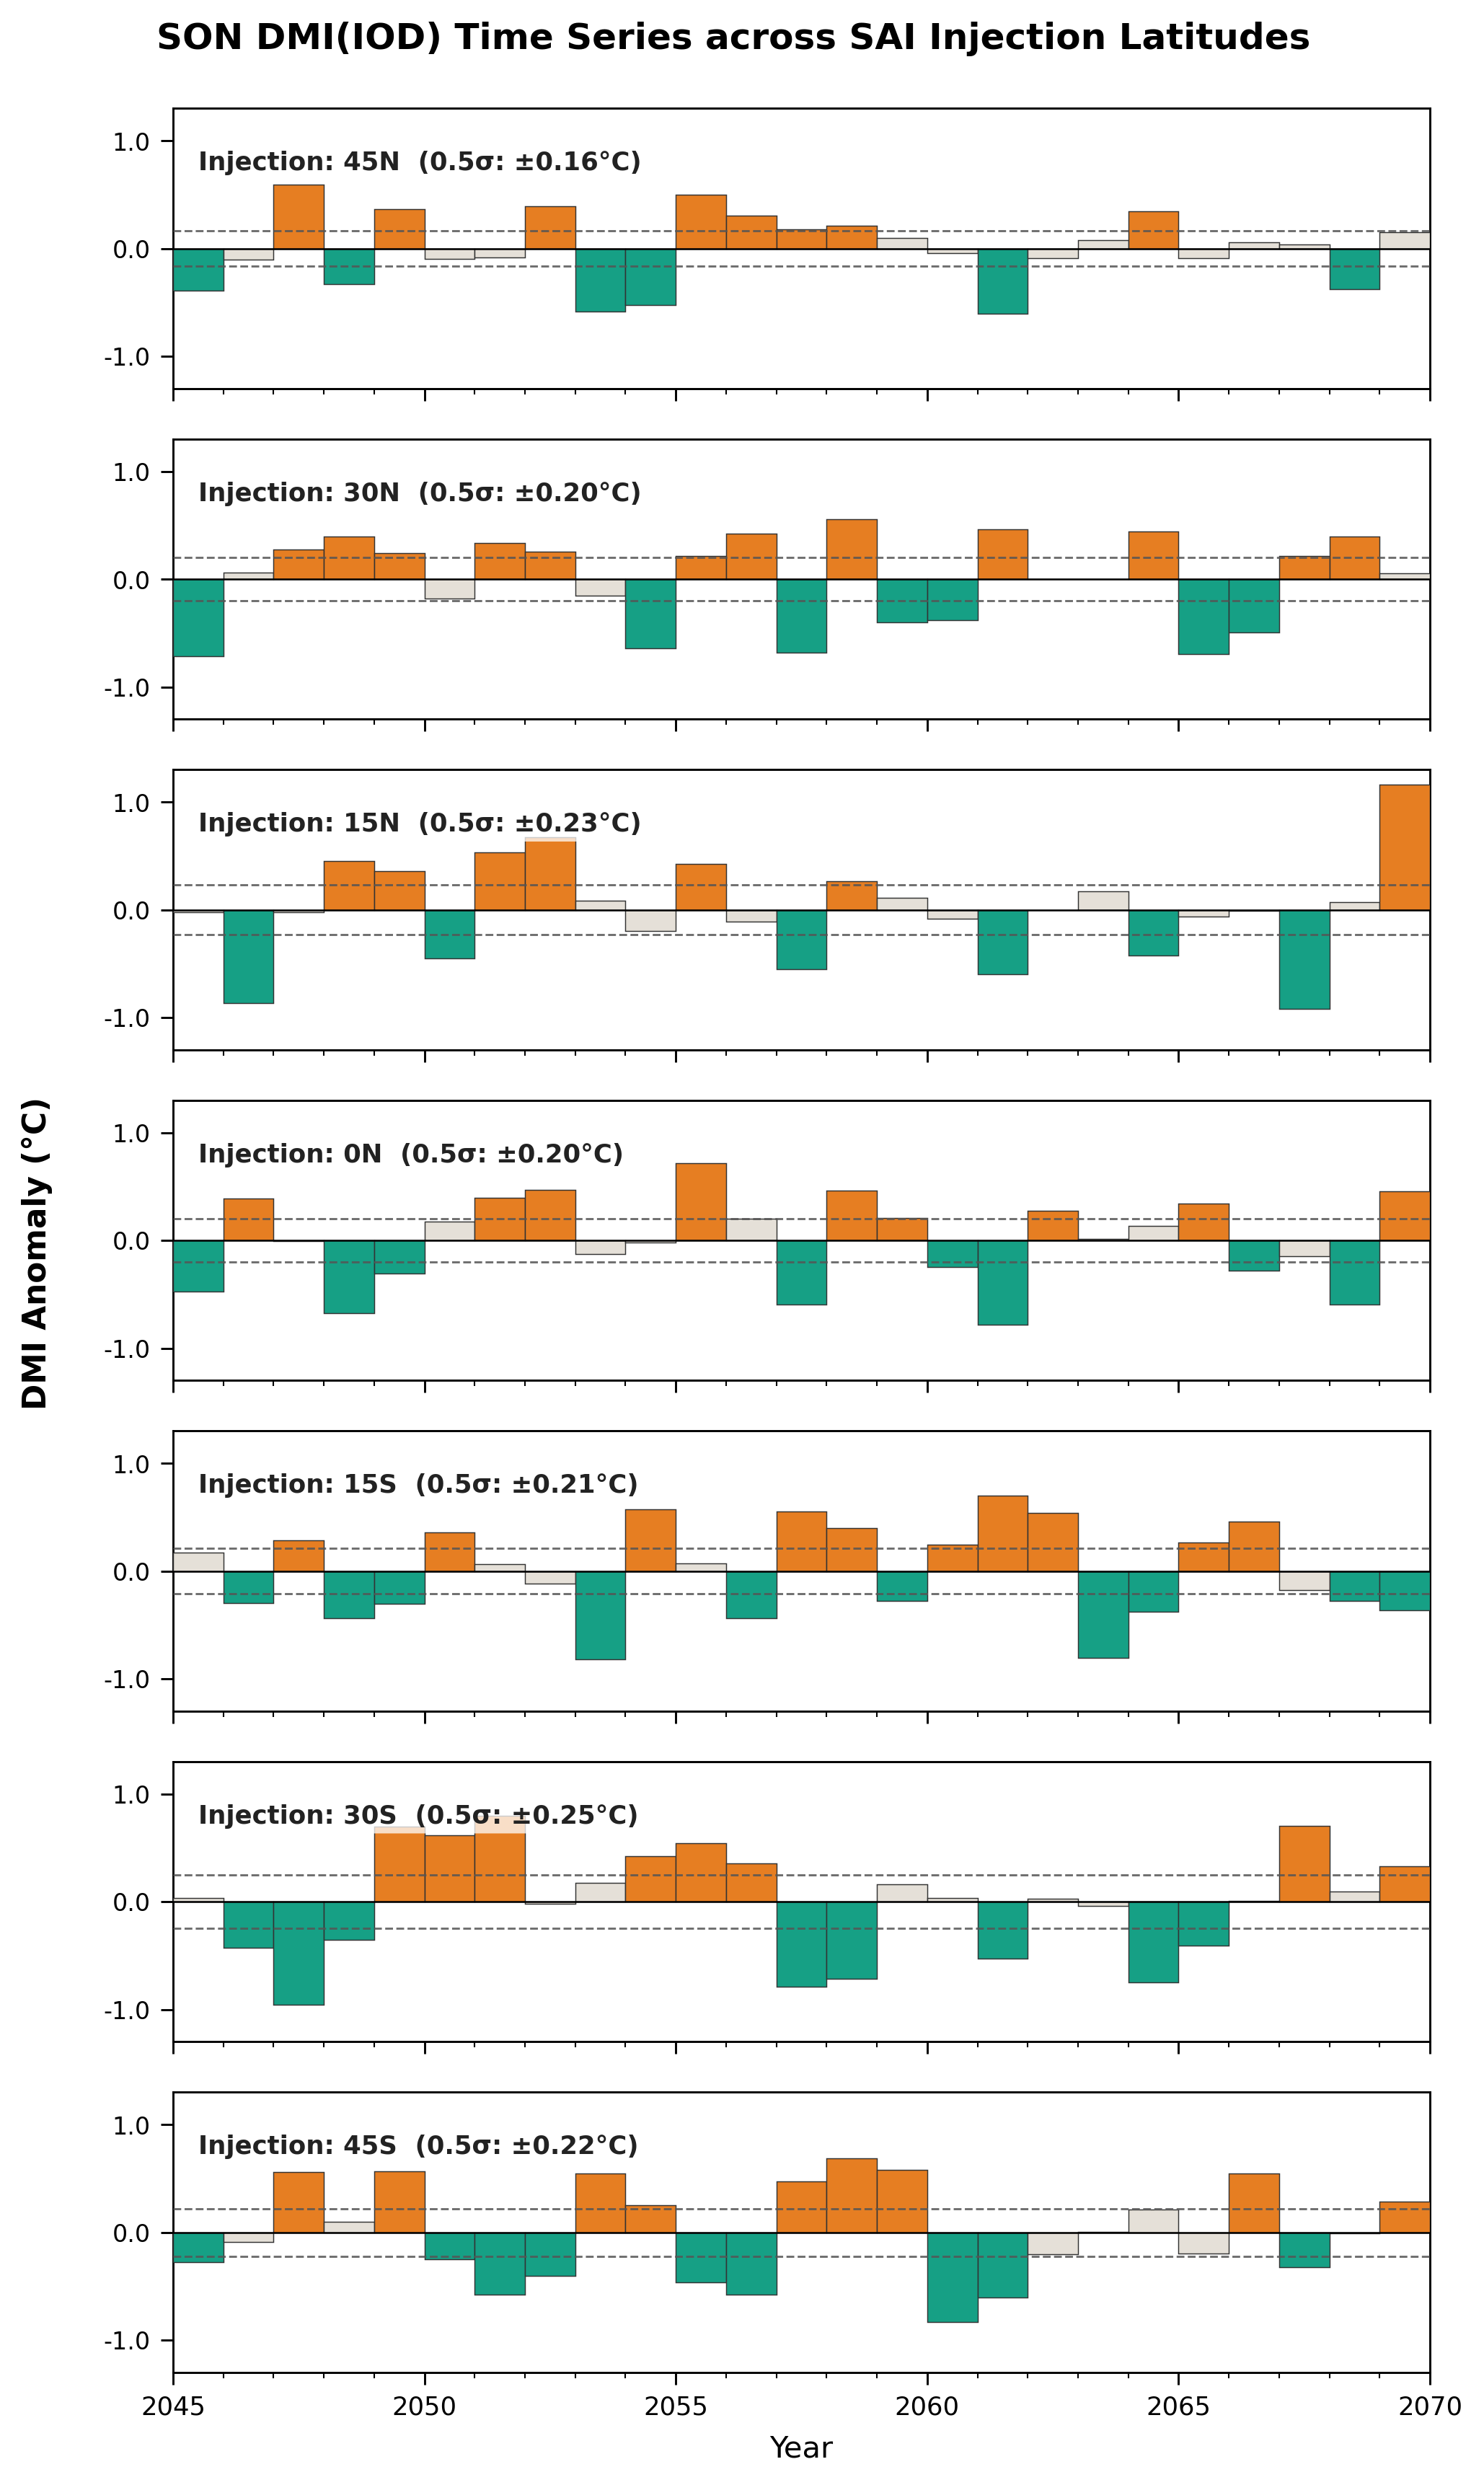

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr


injections = ['45N', '30N', '15N', '0N', '15S', '30S', '45S']

# 7 * 1 프레임
fig, axes = plt.subplots(
    nrows=len(injections),
    ncols=1,
    figsize=(7.0, 11.5),
    dpi=300,
    sharex=True,
    sharey=True,
)


start_year = 2045

for ax, inj in zip(axes, injections):
  file_path = f'dmi_son_{inj}.nc'

  try:
    ds = xr.open_dataset(file_path, decode_times=False)
    var_name = 'DMI' if 'DMI' in ds.variables else 'TS'
    values = ds[var_name].squeeze().values
    n_steps = len(values)
  except FileNotFoundError:

    n_steps = 25
    values = np.zeros(n_steps)

  years = np.arange(start_year, start_year + n_steps)

  # sigma 계산
  sigma = np.nanstd(values)
  th_pos = 0.5 * sigma
  th_neg = -0.5 * sigma


  colors = []
  for v in values:
    if v >= th_pos:
      colors.append('#E67E22')  # Positive IOD
    elif v <= th_neg:
      colors.append('#16A085')  # Negative IOD
    else:
      colors.append('#E5E0D8')  # Neutral

  ax.bar(
      years,
      values,
      color=colors,
      width=1.0,
      edgecolor='#333333',
      linewidth=0.35,
      align='edge',
      zorder=3,
  )

  # +-0.5 sigma 기준선
  ax.axhline(0.0, color='black', linewidth=0.6, zorder=4)
  ax.axhline(
      th_pos,
      color='#555555',
      linestyle='--',
      linewidth=0.7,
      alpha=0.85,
      zorder=4,
  )
  ax.axhline(
      th_neg,
      color='#555555',
      linestyle='--',
      linewidth=0.7,
      alpha=0.85,
      zorder=4,
  )

  ax.text(
      0.02,
      0.78,
      f'Injection: {inj}  (0.5σ: ±{th_pos:.2f}°C)',
      transform=ax.transAxes,
      fontsize=8.5,
      fontweight='bold',
      color='#222222',
      bbox=dict(
          boxstyle='round,pad=0.2',
          facecolor='white',
          edgecolor='none',
          alpha=0.75,
      ),
      zorder=5,
  )

  # 개별 y축
  ax.set_ylim(-1.3, 1.3)
  ax.set_yticks([-1.0, 0.0, 1.0])
  ax.set_yticklabels(['-1.0', '0.0', '1.0'], fontsize=8)

  ax.tick_params(
      which='major',
      direction='out',
      length=4,
      width=0.7,
      top=False,
      right=False,
  )
  ax.tick_params(
      which='minor',
      direction='out',
      length=2,
      width=0.5,
      top=False,
      right=False,
  )

  for spine in ax.spines.values():
    spine.set_linewidth(0.7)

# 공통 x축 
axes[-1].set_xlim(start_year, start_year + n_steps)
major_ticks = np.arange(start_year, start_year + n_steps + 1, 5)
axes[-1].set_xticks(major_ticks)
axes[-1].set_xticks(np.arange(start_year, start_year + n_steps + 1, 1), minor=True)
axes[-1].set_xticklabels(major_ticks, fontsize=8.5)
axes[-1].set_xlabel('Year', fontsize=10, labelpad=5)

# 공통 y축
fig.text(
    0.03,
    0.5,
    'DMI Anomaly (°C)',
    va='center',
    rotation='vertical',
    fontsize=10.5,
    fontweight='bold',
)

# 메인 제목
fig.suptitle(
    'SON DMI(IOD) Time Series across SAI Injection Latitudes',
    fontsize=12,
    fontweight='bold',
    y=0.995,
)

# 여백 조정 (Y축 라벨 공간 확보 및 서브플롯 간격 최적화)
plt.subplots_adjust(
    left=0.13, right=0.96, top=0.96, bottom=0.05, hspace=0.18
)
plt.savefig('dmi_son_timeseries.png', dpi=300)
plt.show()

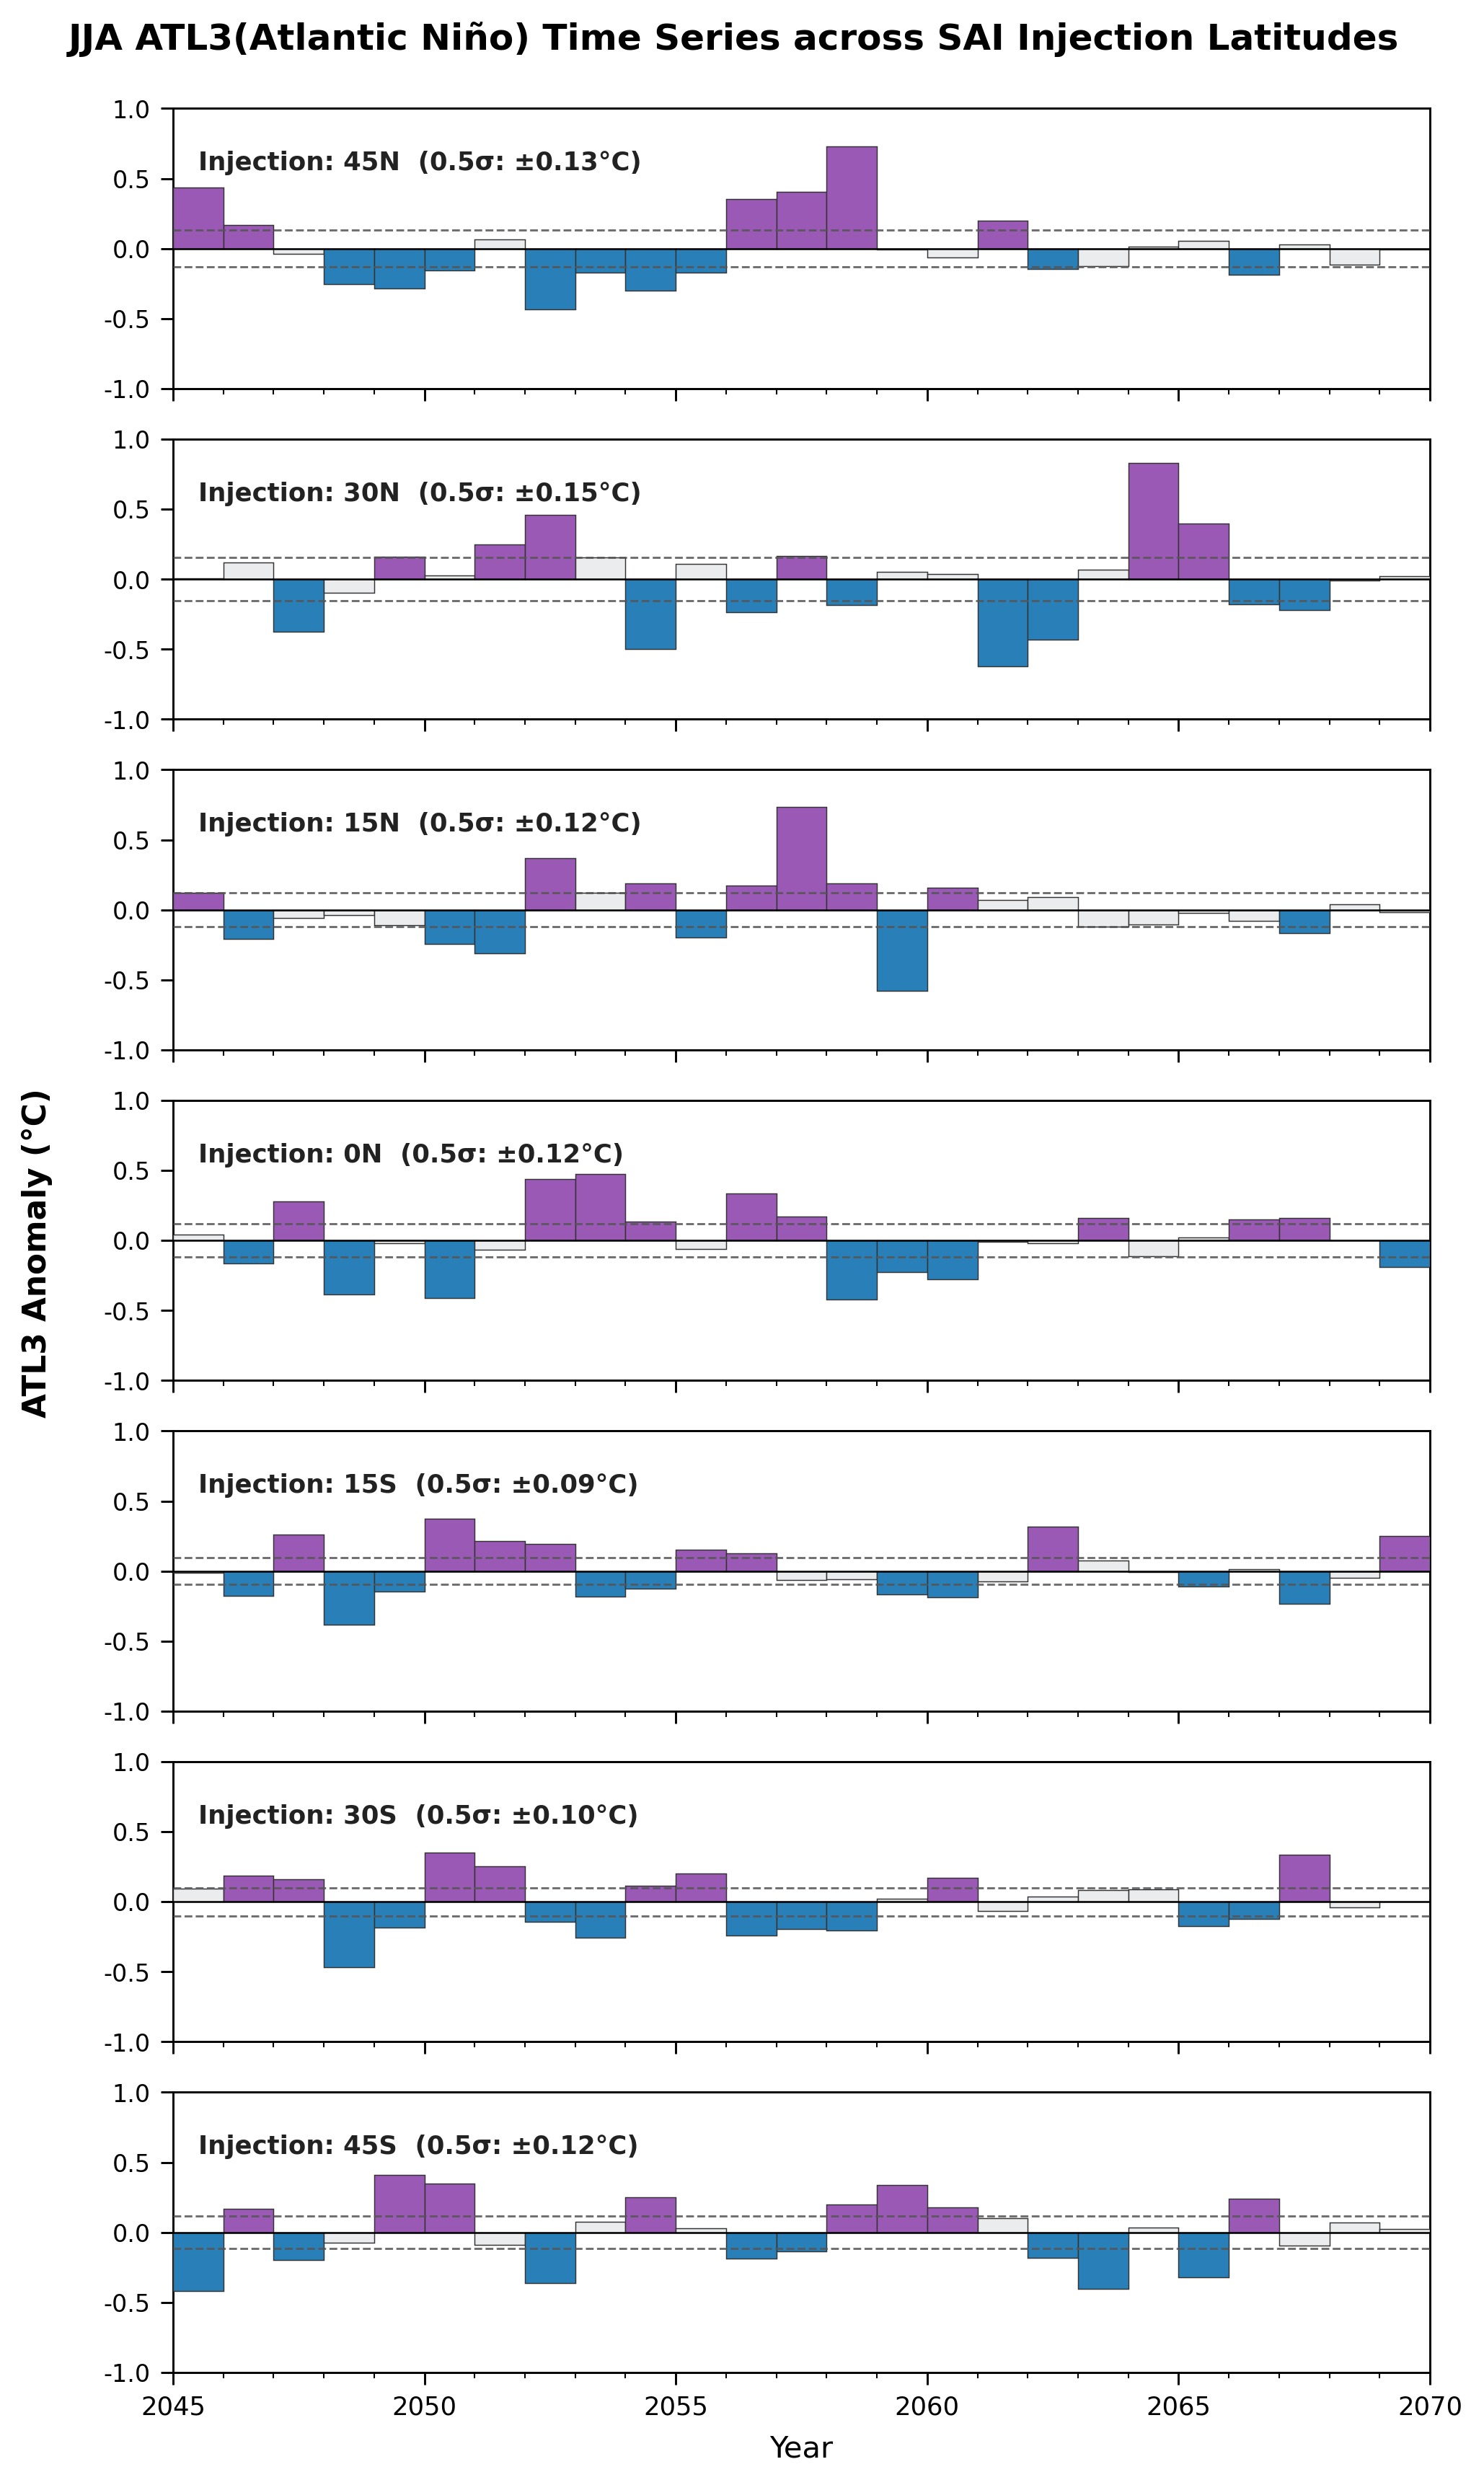

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

injections = ['45N', '30N', '15N', '0N', '15S', '30S', '45S']

# 7 * 1 프레임
fig, axes = plt.subplots(
    nrows=len(injections),
    ncols=1,
    figsize=(7.0, 11.5),
    dpi=300,
    sharex=True,
    sharey=True,
)


start_year = 2045

for ax, inj in zip(axes, injections):
  file_path = f'atl3_jja_{inj}.nc'

  try:
    ds = xr.open_dataset(file_path, decode_times=False)
    var_name = 'ATL3' if 'ATL3' in ds.variables else 'TS'
    values = ds[var_name].squeeze().values
    n_steps = len(values)
  except FileNotFoundError:
    n_steps = 25
    values = np.zeros(n_steps)

  years = np.arange(start_year, start_year + n_steps)

  #  sigma 계산
  sigma = np.nanstd(values)
  th_pos = 0.5 * sigma
  th_neg = -0.5 * sigma

  colors = []
  for v in values:
    if v >= th_pos and th_pos > 0:
      colors.append('#9B59B6')  # Atlantic nino
    elif v <= th_neg and th_neg < 0:
      colors.append('#2980B9')  # Atlantic nina
    else:
      colors.append('#EAECEE')  # Neutral


  ax.bar(
      years,
      values,
      color=colors,
      width=1.0,
      edgecolor='#333333',
      linewidth=0.35,
      align='edge',
      zorder=3,
  )

  # +-0.5 sigma 계산
  ax.axhline(0.0, color='black', linewidth=0.6, zorder=4)
  ax.axhline(
      th_pos,
      color='#555555',
      linestyle='--',
      linewidth=0.7,
      alpha=0.85,
      zorder=4,
  )
  ax.axhline(
      th_neg,
      color='#555555',
      linestyle='--',
      linewidth=0.7,
      alpha=0.85,
      zorder=4,
  )


  ax.text(
      0.02,
      0.78,
      f'Injection: {inj}  (0.5σ: ±{th_pos:.2f}°C)',
      transform=ax.transAxes,
      fontsize=8.5,
      fontweight='bold',
      color='#222222',
      bbox=dict(
          boxstyle='round,pad=0.2',
          facecolor='white',
          edgecolor='none',
          alpha=0.75,
      ),
      zorder=5,
  )

  # 개별 y축
  ax.set_ylim(-1.0, 1.0)
  ax.set_yticks([-1.0,-0.5, 0.0,0.5, 1.0])
  ax.set_yticklabels(['-1.0','-0.5', '0.0','0.5', '1.0'], fontsize=8)

  ax.tick_params(
      which='major',
      direction='out',
      length=4,
      width=0.7,
      top=False,
      right=False,
  )
  ax.tick_params(
      which='minor',
      direction='out',
      length=2,
      width=0.5,
      top=False,
      right=False,
  )

  for spine in ax.spines.values():
    spine.set_linewidth(0.7)

# 공통 x축
axes[-1].set_xlim(start_year, start_year + n_steps)
major_ticks = np.arange(start_year, start_year + n_steps + 1, 5)
axes[-1].set_xticks(major_ticks)
axes[-1].set_xticks(np.arange(start_year, start_year + n_steps + 1, 1), minor=True)
axes[-1].set_xticklabels(major_ticks, fontsize=8.5)
axes[-1].set_xlabel('Year', fontsize=10, labelpad=5)

# 공통 y축
fig.text(
    0.03,
    0.5,
    'ATL3 Anomaly (°C)',
    va='center',
    rotation='vertical',
    fontsize=10.5,
    fontweight='bold',
)

# 메인 제목
fig.suptitle(
    'JJA ATL3(Atlantic Niño) Time Series across SAI Injection Latitudes',
    fontsize=12,
    fontweight='bold',
    y=0.995,
)

plt.subplots_adjust(
    left=0.13, right=0.96, top=0.96, bottom=0.05, hspace=0.18
)
plt.savefig('atl3_jja_timeseries.png', dpi=300)
plt.show()